# 03. SARIMA, Holt-Winters and SARIMAX (daily)

Verdict: The SARIMAX with temperature and holidays is our best honest daily model, just ahead of the AR, but even with a perfect weather forecast it only matches RTE raw. MAE test: SARIMAX persistence 1.65 GW vs RTE raw 1.16 GW (+42.5 %).

Setup: Cutoff D 12:00, forecast the 24 h of D+1, test 1 Jul 2025 to 30 Jun 2026.
Daily mean in GW (course milestones m2/m3), not comparable with the hourly MW of other notebooks.

## 1. Setup

Same frame as 02_ar: daily mean in GW, train 1 Jan 2023 to 30 Jun 2025, test 1 Jul 2025 to 30 Jun 2026. Each day T is forecast 2 steps ahead from T-2.

Parameters are estimated once on the train. For each test day the model is re-run with frozen parameters on data up to T-2 (watt_forecast.models.sarima). No refit in the loop.

In [1]:
import sys
sys.path.insert(0, "../src")

import warnings
from datetime import date, timedelta

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.stattools import adfuller
from statsmodels.tools.sm_exceptions import EstimationWarning
from watt_forecast.data_preprocessing import DAILY_KEYS, load_daily, save_predictions
from watt_forecast.features import daily_exog
from watt_forecast.metrics import compute_metrics, scorecard_daily
from watt_forecast.models.ar import seasonal_normal, ar_forecast
from watt_forecast.models.sarima import rolling_forecast, hw_rolling_forecast

TRAIN_START, TRAIN_END = date(2023, 1, 1), date(2025, 6, 30)
TEST_START, TEST_END = date(2025, 7, 1), date(2026, 6, 30)
H = 2  # T is forecast from T-2

warnings.simplefilter("ignore", EstimationWarning)  # bad starting values replaced by zeros before the fit

pl.Config.set_tbl_rows(20)
plt.rcParams["figure.figsize"] = (12, 4)

In [2]:
daily = load_daily().filter(pl.col("date").is_between(TRAIN_START, TEST_END))
train_mask = (daily["date"] <= TRAIN_END).to_numpy()
test_pos = np.where(~train_mask)[0]
y = daily["target"].to_numpy()
y_train = y[train_mask]

assert (daily["date"].diff().drop_nulls() == timedelta(days=1)).all(), "the daily series should have no gap"
assert len(test_pos) == 365, "the test period should have 365 days"
print(daily.height, "days |", len(y_train), "train days |", len(test_pos), "test days")

1277 days | 912 train days | 365 test days


## 2. Model

### SARIMA

The weekly difference is stationary (ADF) and its ACF suggests a seasonal MA(1), so we fix \((0, 1, 1)_7\) and pick \(p, q \in \{0, 1, 2\}\) by AIC. Details in the appendix.

In [3]:
SEASONAL = (0, 1, 1, 7)

grid = []
for p in range(3):
    for q in range(3):
        fit = SARIMAX(y_train, order=(p, 0, q), seasonal_order=SEASONAL).fit(disp=False, maxiter=200)
        grid.append({"p": p, "q": q, "AIC": fit.aic})
grid = pl.DataFrame(grid).sort("AIC")

ORDER = (grid["p"][0], 0, grid["q"][0])
print("best order:", ORDER, "x", SEASONAL)

best order: (2, 0, 2) x (0, 1, 1, 7)


In [4]:
res_sarima = SARIMAX(y_train, order=ORDER, seasonal_order=SEASONAL).fit(disp=False, maxiter=200)
assert res_sarima.mle_retvals["converged"], "the SARIMA fit did not converge"
print(dict(zip(res_sarima.param_names, res_sarima.params.round(3))))

# The first 8 residuals are distorted by the start of the weekly difference
resid = res_sarima.resid[8:]
resid_dates = daily["date"].filter(pl.Series(train_mask))[8:]
assert len(resid) == len(resid_dates) == len(y_train) - 8, "one residual per train day after the first 8"

{'ar.L1': np.float64(1.811), 'ar.L2': np.float64(-0.813), 'ma.L1': np.float64(-0.64), 'ma.L2': np.float64(-0.225), 'ma.S.L7': np.float64(-1.0), 'sigma2': np.float64(3.093)}


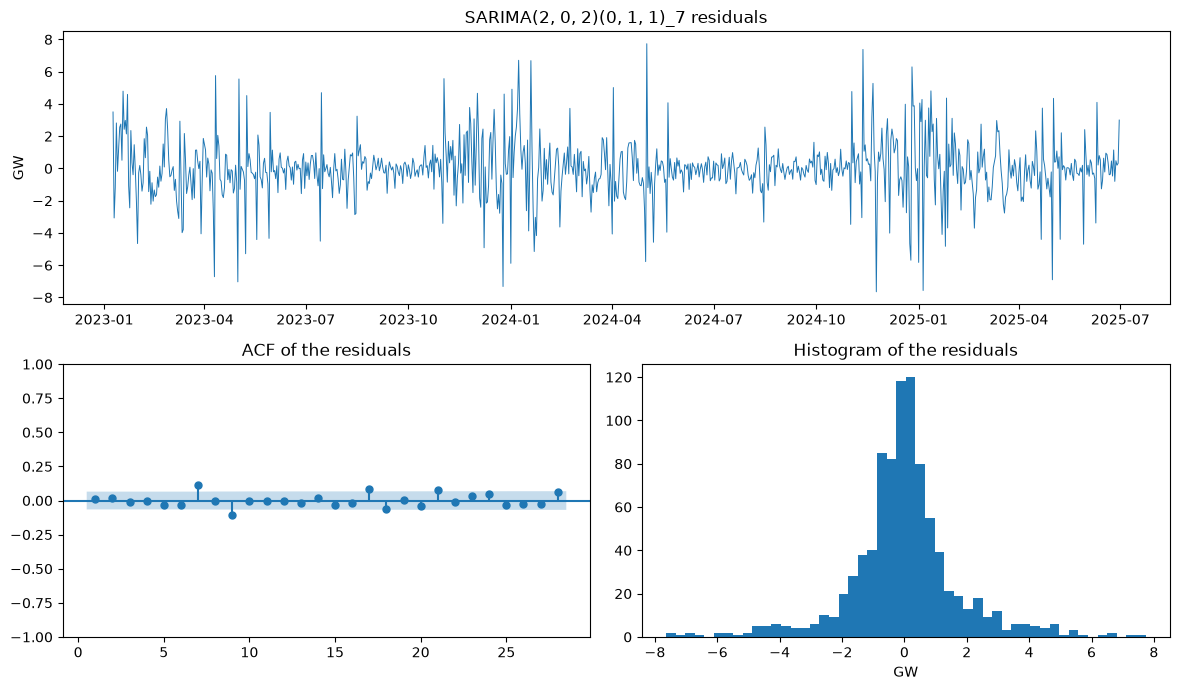

In [5]:
fig = plt.figure(figsize=(12, 7))
ax_time = fig.add_subplot(2, 1, 1)
ax_time.plot(resid_dates, resid, lw=0.7)
ax_time.set_title(f"SARIMA{ORDER}{SEASONAL[:3]}_7 residuals")
ax_time.set_ylabel("GW")
plot_acf(resid, lags=28, zero=False, ax=fig.add_subplot(2, 2, 3), title="ACF of the residuals")
ax_hist = fig.add_subplot(2, 2, 4)
ax_hist.hist(resid, bins=50)
ax_hist.set_title("Histogram of the residuals")
ax_hist.set_xlabel("GW")
plt.tight_layout()
plt.show()

In [6]:
n_arma = ORDER[0] + ORDER[2] + SEASONAL[2]  # estimated ARMA coefficients
acorr_ljungbox(resid, lags=[7, 14], model_df=n_arma)

,lb_stat,lb_pvalue
7,13.996884,0.000913
14,24.455775,0.003636


Ljung-Box rejects white noise at lags 7 and 14 (p-values 0.001 and 0.004). Residuals are bigger in winter with heavy tails (a few days at ±6 to 8 GW). Fine on normal days, misses the big events.

\(\hat\phi_1 + \hat\phi_2 \approx 1.0\), so the AR part is close to a unit root, and the seasonal MA is at -1.0, which means a fixed weekly profile.

### Holt-Winters

Additive weekly seasonality, with or without a damped trend, chosen by AIC (see A.5).

In [7]:
hw_fits = {
    "no trend": ExponentialSmoothing(y_train, seasonal="add", seasonal_periods=7).fit(),
    "damped trend": ExponentialSmoothing(
        y_train, trend="add", damped_trend=True, seasonal="add", seasonal_periods=7
    ).fit(),
}

hw_table = pl.DataFrame([
    {
        "model": name,
        "AIC": fit.aic,
        "alpha_(level)": fit.params["smoothing_level"],
        "beta_(trend)": fit.params["smoothing_trend"],
        "gamma_(season)": fit.params["smoothing_seasonal"],
        "phi_(damping)": fit.params["damping_trend"],
    }
    for name, fit in hw_fits.items()
]).sort("AIC")
hw_name = hw_table["model"][0]
res_hw = hw_fits[hw_name]
print("chosen:", hw_name)

chosen: damped trend


### SARIMAX with temperature and holidays

Same order plus heating = max(0, 15 - T), cooling = max(0, T - 22) (L4 thresholds) and holiday (11 French public holidays), from watt_forecast.features.daily_exog. Regression with SARIMA errors.

In [8]:
EXOG_COLS = ["heating", "cooling", "holiday"]
exog = daily_exog(daily)
X = exog.select(EXOG_COLS).to_numpy().astype(float)

assert exog.filter(pl.col("date") == date(2025, 7, 14))["holiday"].item() == 1, "14 July is a holiday"
assert exog.filter(pl.col("date") == date(2025, 7, 15))["holiday"].item() == 0, "15 July is not"
assert ((exog["heating"] > 0) & (exog["cooling"] > 0)).sum() == 0, "a day cannot need heating and cooling"
print("holidays in the test period:", exog["holiday"].to_numpy()[test_pos].sum())

res_sarimax = SARIMAX(y_train, exog=X[train_mask], order=ORDER, seasonal_order=SEASONAL).fit(disp=False, maxiter=200)
assert res_sarimax.mle_retvals["converged"], "the SARIMAX fit did not converge"
names = EXOG_COLS + res_sarimax.param_names[len(EXOG_COLS):]  # x1, x2, x3 are the regressors
print(dict(zip(names, res_sarimax.params.round(3))))
print(f"AIC: SARIMA {res_sarima.aic:.1f}, SARIMAX {res_sarimax.aic:.1f}")

holidays in the test period: 11
{'heating': np.float64(0.749), 'cooling': np.float64(0.287), 'holiday': np.float64(-3.777), 'ar.L1': np.float64(1.849), 'ar.L2': np.float64(-0.851), 'ma.L1': np.float64(-0.7), 'ma.L2': np.float64(-0.185), 'ma.S.L7': np.float64(-0.98), 'sigma2': np.float64(1.197)}
AIC: SARIMA 3635.1, SARIMAX 2770.8


Each heating degree adds about 0.75 GW, each cooling degree about 0.29 GW, and a holiday removes about 3.8 GW (roughly a weekday vs a Sunday). AIC goes from 3,635 to 2,771 and the noise variance from 3.1 to 1.2 GW². All 11 test-year holidays are flagged.

### Two versions of the temperature

- a) Observed temperature of T: a perfect weather forecast, not known at the cutoff, so only an upper bound.
- b) Persistence (honest): temperature of T-2 used for T-1 and T. holiday stays, the calendar is known.

In [9]:
# Row of day T = heating and cooling computed from the temperature of T-2, holiday of T
X_persist = (
    daily_exog(daily.with_columns(pl.col("temperature_c").shift(H)))
    .select(EXOG_COLS).to_numpy().astype(float)
)

i0 = test_pos[0]
assert np.allclose(X_persist[i0, :2], X[i0 - H, :2]), "the degrees of T should come from T-2"
assert X_persist[i0, 2] == X[i0, 2], "holiday should stay the one of T"
assert not np.isnan(X_persist[test_pos]).any(), "no missing regressor on the test period"

### Day-ahead forecasts on the test year

Seasonal naive (T-7), AR(8) + normal from 02_ar, SARIMA, Holt-Winters, the two SARIMAX versions, and RTE raw (daily mean).

In [10]:
# AR(8) + normal, as in 02_ar
P_AR = 8
normal = seasonal_normal(daily, TRAIN_END).to_numpy()
anom = y - normal
res_ar = AutoReg(anom[train_mask], lags=P_AR).fit()
pred_ar = [ar_forecast(res_ar.params, anom[i - P_AR - 1:i - 1], H)[-1] + normal[i] for i in test_pos]

pred_sarima = rolling_forecast(res_sarima, y, None, test_pos, h=H)
pred_hw = hw_rolling_forecast(res_hw, y, test_pos, h=H)
pred_sarimax_obs = rolling_forecast(res_sarimax, y, X, test_pos, h=H)
pred_sarimax_persist = rolling_forecast(res_sarimax, y, X, test_pos, h=H, exog_future=X_persist)

In [11]:
# Cutoff check: changing every value after T-2 must not change the forecast of T
i = test_pos[100]
y_changed = y.copy()
y_changed[i - 1:] = 0
assert np.isclose(rolling_forecast(res_sarima, y_changed, None, [i], h=H)[0], pred_sarima[100]), "SARIMA uses data after T-2"
assert np.isclose(hw_rolling_forecast(res_hw, y_changed, [i], h=H)[0], pred_hw[100]), "Holt-Winters uses data after T-2"
assert np.isclose(
    rolling_forecast(res_sarimax, y_changed, X, [i], h=H, exog_future=X_persist)[0], pred_sarimax_persist[100]
), "SARIMAX uses data after T-2"

In [12]:
daily = daily.with_columns(pl.col("target").shift(7).alias("naive_7d_gw"))
test = (
    daily.filter(pl.col("date").is_between(TEST_START, TEST_END))
    .with_columns(
        pl.Series("ar_gw", pred_ar),
        pl.Series("sarima_gw", pred_sarima),
        pl.Series("hw_gw", pred_hw),
        pl.Series("sarimax_persist_gw", pred_sarimax_persist),
        pl.Series("sarimax_obs_gw", pred_sarimax_obs),
    )
)

forecasts = {
    "Seasonal naive (T-7)": "naive_7d_gw",
    f"AR({P_AR}) + normal": "ar_gw",
    "SARIMA": "sarima_gw",
    "Holt-Winters": "hw_gw",
    "SARIMAX persistence": "sarimax_persist_gw",
    "SARIMAX observed temp. (upper bound)": "sarimax_obs_gw",
    "RTE raw": "rte_gw",
}
assert test.height == 365, "one forecast per test day"
assert test.select(forecasts.values()).null_count().sum_horizontal().item() == 0, "no missing forecast"

In [13]:
# Test forecasts of this notebook, read by 06_comparison (the naive, AR and RTE ones are saved by 02_ar)
own = {name: forecasts[name] for name in ["SARIMA", "Holt-Winters", "SARIMAX persistence", "SARIMAX observed temp. (upper bound)"]}
save_predictions(test, own, "03_sarima", keys=DAILY_KEYS)

## 3. Results vs benchmark

The full comparison is in 06_comparison.

In [14]:
scorecard_daily(test, {"RTE raw": "rte_gw", **own})

forecast,MAE,bias,vs_reference_(%)
str,f64,f64,f64
"""RTE raw""",1.16,-1.09,0.0
"""SARIMA""",1.79,-0.01,54.7
"""Holt-Winters""",1.83,0.01,58.1
"""SARIMAX persistence""",1.65,-0.0,42.5
"""SARIMAX observed temp. (upper …",1.16,-0.01,0.2


SARIMA (1.79 GW) and Holt-Winters (1.83 GW) are a bit worse than the AR(8) + normal (1.69 GW). The honest SARIMAX is our best honest model, but only just (1.65 GW). With the observed temperature it drops to 1.16 GW, the level of RTE raw.

## 4. Where it fails

A cold week: 5 to 11 January 2026.

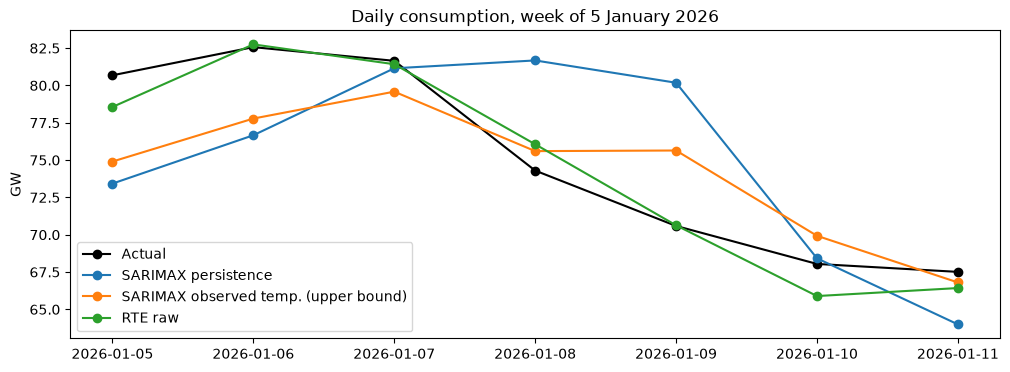

In [15]:
week = test.filter(pl.col("date").is_between(date(2026, 1, 5), date(2026, 1, 11)))

plt.plot(week["date"], week["target"], color="k", marker="o", label="Actual")
plt.plot(week["date"], week["sarimax_persist_gw"], marker="o", label="SARIMAX persistence")
plt.plot(week["date"], week["sarimax_obs_gw"], marker="o", label="SARIMAX observed temp. (upper bound)")
plt.plot(week["date"], week["rte_gw"], marker="o", label="RTE raw")
plt.title("Daily consumption, week of 5 January 2026")
plt.ylabel("GW")
plt.legend()
plt.show()

Same two-day delay as the AR. The honest SARIMAX is 7 GW too low on the cold Monday (73.4 vs 80.7 GW) and almost 10 GW too high on Friday (80.2 vs 70.6 GW). With observed temperature the delay is gone but the coldest days are still about 5 GW low. RTE raw stays within about 2 GW.

## 5. Conclusion

- SARIMA(2, 0, 2)(0, 1, 1)\(_7\) and Holt-Winters both boil down to a fixed weekly profile on a very persistent level, and neither beats the AR(8) + normal.
- Temperature and holidays help a lot in-sample, but with the T-2 temperature the gain is small (1.65 GW). A perfect weather forecast would be worth about 0.5 GW, mostly in winter, and only gets us to RTE raw.
- Kept for next step: the temperature and holiday regressors. For m4 we move to hourly data (the desk needs 24 hours) with LightGBM, lags 48 h / 168 h and the watt_forecast.features, evaluated walk-forward.

## Appendix

### A.1 Stationarity

ADF (H0: unit root) on the raw train series and on \(w_t = y_t - y_{t-7}\).

In [16]:
w_train = y_train[7:] - y_train[:-7]
assert len(w_train) == len(y_train) - 7, "a weekly difference costs 7 values"

pl.DataFrame({
    "series": ["daily consumption (train)", "weekly difference (train)"],
    "ADF_p-value": [adfuller(y_train, result_object=True).pvalue, adfuller(w_train, result_object=True).pvalue],
})

series,ADF_p-value
str,f64
"""daily consumption (train)""",0.053894
"""weekly difference (train)""",2.9921e-8


Raw series p-value is 0.054, so no rejection at 5 % (2.5 years is short for a yearly cycle). The weekly difference is clearly stationary (around 3e-8), so \(D = 1\) at lag 7, no regular difference.

### A.2 ACF and PACF of the weekly difference

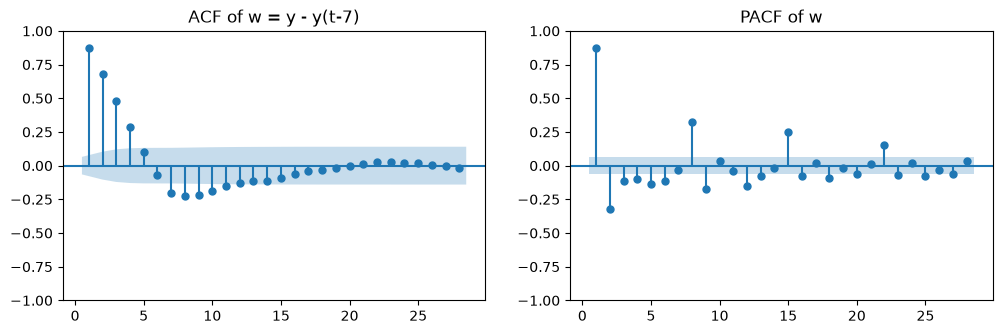

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
plot_acf(w_train, lags=28, zero=False, ax=ax[0], title="ACF of w = y - y(t-7)")
plot_pacf(w_train, lags=28, zero=False, ax=ax[1], title="PACF of w")
plt.show()

ACF decays over the first lags (0.88, 0.68, 0.48, ...), so a regular AR term, and the negative bar at lag 7 (about -0.2) points to a seasonal MA(1). PACF suggests p = 1 or 2.

### A.3 AIC grid

Seasonal part fixed to \((0, 1, 1)_7\), search on \(p, q \in \{0, 1, 2\}\). Same differencing everywhere so the AICs are comparable.

In [18]:
grid.with_columns(pl.col("AIC").round(1), (pl.col("AIC") - pl.col("AIC").min()).round(1).alias("AIC_-_min"))

p,q,AIC,AIC_-_min
i64,i64,f64,f64
2,2,3635.1,0.0
1,1,3638.0,3.0
1,2,3639.7,4.6
2,1,3639.8,4.7
2,0,3641.7,6.6
1,0,3674.1,39.0
0,2,4177.0,541.9
0,1,4584.8,949.7
0,0,5382.8,1747.7


p = 0 is much worse, demand has strong day-to-day memory. Best is SARIMA(2, 0, 2)(0, 1, 1)\(_7\). The TP03 model SARIMA(1, 0, 1) is only 3 points behind, but we keep the best one as planned.

### A.4 Top 5 residuals of the SARIMA

In [19]:
holidays = daily_exog(daily).select("date", "holiday")

top_resid = (
    pl.DataFrame({"date": resid_dates, "residual_gw": resid})
    .sort(pl.col("residual_gw").abs(), descending=True)
    .head(5)
    .join(daily.select("date", "temperature_c"), on="date")
    .join(holidays, on="date")
    .with_columns(pl.col("date").dt.strftime("%A").alias("weekday"))
)
top_resid.with_columns(pl.col("residual_gw", "temperature_c").round(2))

date,residual_gw,temperature_c,holiday,weekday
date,f64,f64,i8,str
2023-12-25,-7.32,9.71,1,"""Monday"""
2024-05-02,7.73,11.77,0,"""Thursday"""
2024-11-12,7.38,8.68,0,"""Tuesday"""
2024-11-24,-7.64,14.47,0,"""Sunday"""
2025-01-05,-7.57,9.87,0,"""Sunday"""


Same story as 02_ar. 25 Dec 2023 is a holiday, 2 May and 12 Nov 2024 are days after a holiday, 24 Nov 2024 and 5 Jan 2025 follow an 8 to 9 °C warm-up in one day. No temperature, no chance.

### A.5 Holt-Winters in detail

In [20]:
hw_table.with_columns(pl.exclude("model").round(3))

model,AIC,alpha_(level),beta_(trend),gamma_(season),phi_(damping)
str,f64,f64,f64,f64,f64
"""damped trend""",1095.278,1.0,0.0,0.0,0.906
"""no trend""",1095.317,1.0,NaN,0.0,NaN


AICs are basically equal (1095.28 vs 1095.32) and the damped trend does nothing (\(\hat\beta = 0\)). With \(\hat\alpha = 1\) and \(\hat\gamma = 0\) it's a naive forecast plus a fixed weekly profile, like in TP03.

### A.6 All metrics on the test year

In [21]:
results = pl.DataFrame(
    [{"forecast": name, **compute_metrics(test, col, actual_col="target")} for name, col in forecasts.items()]
)
results.select("forecast", "MAE", "bias", "RMSE", "MAPE").with_columns(pl.col("MAE", "bias", "RMSE", "MAPE").round(2))

forecast,MAE,bias,RMSE,MAPE
str,f64,f64,f64,f64
"""Seasonal naive (T-7)""",3.29,-0.05,4.88,6.12
"""AR(8) + normal""",1.69,-0.17,2.44,3.2
"""SARIMA""",1.79,-0.01,2.58,3.41
"""Holt-Winters""",1.83,0.01,2.65,3.49
"""SARIMAX persistence""",1.65,-0.0,2.41,3.08
"""SARIMAX observed temp. (upper …",1.16,-0.01,1.62,2.22
"""RTE raw""",1.16,-1.09,1.34,2.35


The AR wins over SARIMA and Holt-Winters because its normal carries the yearly cycle. All three are unbiased, unlike RTE raw. The honest SARIMAX gains little since the T-2 temperature mostly repeats what the AR part already knows.

### A.7 MAE by month

In [22]:
by_month = {
    "SARIMA": "sarima_gw",
    "SARIMAX persistence": "sarimax_persist_gw",
    "SARIMAX observed temp.": "sarimax_obs_gw",
}
mae_by_month = (
    test.group_by(pl.col("date").dt.strftime("%Y-%m").alias("month"))
    .agg(
        *[(pl.col(col) - pl.col("target")).abs().mean().alias(name.replace(" ", "_")) for name, col in by_month.items()],
        pl.col("temperature_c").mean().alias("mean_temp_(°C)"),
    )
    .sort("month")
)
mae_by_month.with_columns(pl.exclude("month").round(2))

month,SARIMA,SARIMAX_persistence,SARIMAX_observed_temp.,mean_temp_(°C)
str,f64,f64,f64,f64
"""2025-07""",1.36,1.03,0.8,21.44
"""2025-08""",1.06,0.96,0.93,21.78
"""2025-09""",0.71,0.65,0.56,16.46
"""2025-10""",0.83,0.74,0.59,13.14
"""2025-11""",3.09,2.95,2.14,9.05
"""2025-12""",2.57,2.45,1.44,7.04
"""2026-01""",2.94,2.89,2.06,5.25
"""2026-02""",2.24,2.29,1.48,8.89
"""2026-03""",1.73,1.76,1.03,9.61


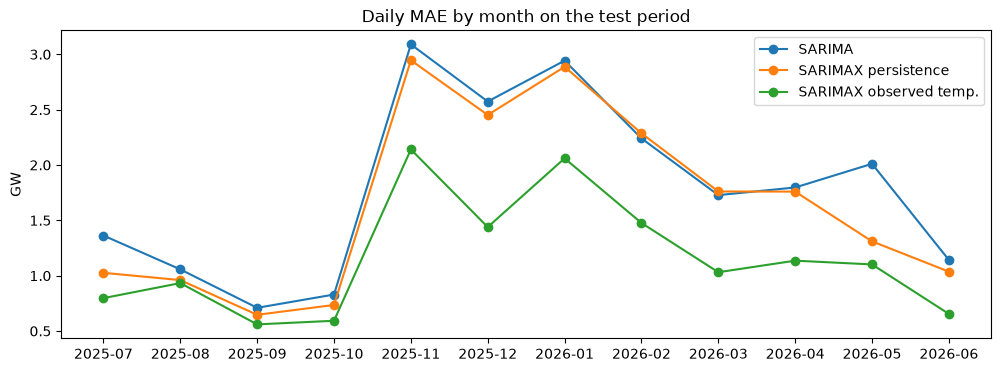

In [23]:
for name in by_month:
    plt.plot(mae_by_month["month"], mae_by_month[name.replace(" ", "_")], marker="o", label=name)
plt.title("Daily MAE by month on the test period")
plt.ylabel("GW")
plt.legend()
plt.show()

The holiday regressor shows in May (2.01 to 1.31 GW, four holidays this year) and July (14 July). In winter the honest SARIMAX is barely better than the SARIMA (0.1 GW at most), and the gap to the upper bound is 0.8 to 1.0 GW per month from November to February. That's where a weather forecast would help most.

### A.8 Winter 2025-2026

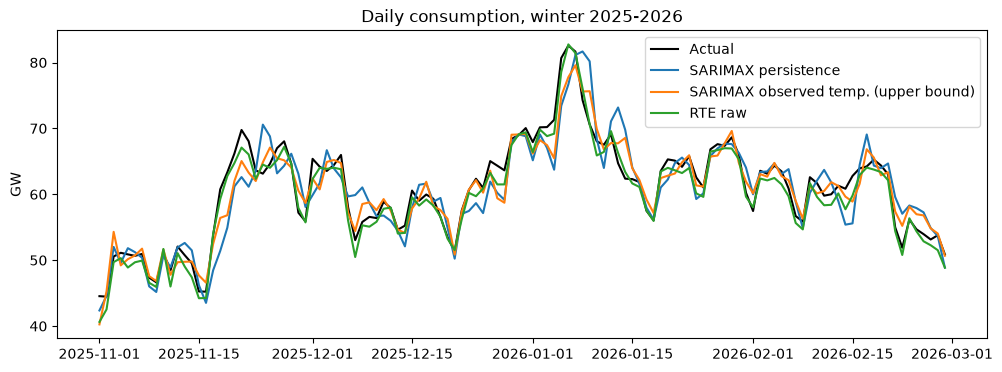

In [24]:
winter = test.filter(pl.col("date").is_between(date(2025, 11, 1), date(2026, 2, 28)))

plt.plot(winter["date"], winter["target"], color="k", label="Actual")
plt.plot(winter["date"], winter["sarimax_persist_gw"], label="SARIMAX persistence")
plt.plot(winter["date"], winter["sarimax_obs_gw"], label="SARIMAX observed temp. (upper bound)")
plt.plot(winter["date"], winter["rte_gw"], label="RTE raw")
plt.title("Daily consumption, winter 2025-2026")
plt.ylabel("GW")
plt.legend()
plt.show()

Honest SARIMAX lags cold spells by about two days, like the AR (mid-November, early January). With observed temperature it tracks the actual curve, still a few GW short on the early January peak. RTE raw is close, slightly below most of the time.